# Setting up the imported packages

In [1]:
import pathlib
import numpy as np
import scipy as sp
from astropy.io import fits
import matplotlib.pyplot as plt
from scipy import ndimage
from astropy.visualization import ImageNormalize, ZScaleInterval

In [2]:
%matplotlib widget

# Define all relevant functions

In [3]:
def load_calibration_image(image_id, folder):
    """Return {file_type: {'data': array, 'header': primary header}} for one image id.

    Handles the three layouts in the data: a 3D image in the primary HDU, a 3D image
    in an extension, or one 2D image extension per chip (stacked into 3D).
    """
    cal = {}
    for file in sorted(folder.rglob(image_id + "_*.fits")):
        file_type = file.stem.split("_", 1)[1]   # 'ubai2505m_maskfile' -> 'maskfile'
        with fits.open(file) as hdul:
            images = [h.data for h in hdul
                      if isinstance(h, (fits.PrimaryHDU, fits.ImageHDU)) and h.data is not None]
            if not images:
                raise ValueError(f"No image data found in {file}")
            data = images[0] if len(images) == 1 else np.stack(images)
            cal[file_type] = {'data': data.copy(), 'header': hdul[0].header.copy()}
    return cal


def apply_mask(cal, defective=2, questionable=256, reject_questionable=False):
    """Mask the raw image with the MASKFILE.

    Defective pixels become NaN. Questionable pixels keep their values unless
    reject_questionable=True, and are returned as a boolean array either way.

    Returns (masked_data, questionable_pixels).
    """
    raw = cal['raw']['data']
    mask = cal['maskfile']['data']

    if raw.shape != mask.shape:
        raise ValueError(f"Raw shape {raw.shape} does not match mask shape {mask.shape}")

    unexpected = set(np.unique(mask)) - {0, defective, questionable}
    if unexpected:
        raise ValueError(f"Mask contains unexpected values: {sorted(unexpected)}")

    data = raw.astype(np.float64)

    bad = mask == defective
    is_questionable = mask == questionable
    if reject_questionable:
        bad = bad | is_questionable

    data[bad] = np.nan
    return data, is_questionable


def save_fits(data, header, path, history=None):
    """Save data with a copy of the header, adding a HISTORY line describing the step."""
    path = pathlib.Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    header = header.copy()
    if history:
        header['HISTORY'] = history
    fits.writeto(path, data, header, overwrite=True)

def subtract_bias_level(data, blev, rows=slice(9, 790), cols=slice(8, 14)):
    """Subtract the bias level measured in the BLEVFILE overscan, separately for even and odd columns.

    data : (chips, rows, cols) float image, e.g. the masked raw data
    blev : (chips, rows, 14) overscan from the BLEVFILE
    rows, cols : overscan region to average (guidance: FITS rows 10-790, columns 9-14)

    Parity uses Python indices throughout: the mean of the Python-even overscan columns is
    subtracted from the Python-even image columns, and likewise for odd. Since FITS numbering
    is Python + 1, this is the same pairing in FITS terms, so no conversion is needed.

    Returns (corrected_data, levels) where levels[chip] = [even_level, odd_level].
    """
    overscan = blev[:, rows, cols].astype(np.float64)
    corrected = data.astype(np.float64)   # new array, so the input stays untouched
    levels = np.empty((data.shape[0], 2))

    for chip in range(data.shape[0]):
        for parity in (0, 1):
            # Position within the overscan slice of the first column with this Python parity
            start = (parity - cols.start) % 2
            level = overscan[chip][:, start::2].mean()
            corrected[chip, :, parity::2] -= level
            levels[chip, parity] = level

    return corrected, levels

def subtract_bias_image(data, bias):
    """Step 4: subtract the BIASFILE, the residual bias pattern left after the bias level."""
    return data - bias


def subtract_dark(data, dark, dark_time, dark_ref_time=1.0):
    """Step 5: subtract the DARKFILE scaled to this exposure's dark time.

    The DARKFILE header has DARKTIME = 1, so it is a dark rate per second; scale it
    by the raw image's DARKTIME (the time the chip collected dark current).
    """
    return data - dark * (dark_time / dark_ref_time)


def apply_flat(data, flat, inverse=True):
    """Step 6: flat-field correction.

    WFPC2 FLATFILEs are inverse flats, so they are multiplied. Multiplying matches the
    pipeline image far better than dividing; set inverse=False to divide as in the guidance formula.
    """
    return data * flat if inverse else data / flat


def photometric_calibration(data, exptime, photflam):
    """Step 8: convert counts to flux density (erg / s / cm^2 / Angstrom) using PHOTFLAM."""
    return data / exptime * photflam


def flux_to_mag(flux, photzpt, zp_corr=0.0):
    """Step 8: convert flux density to STMAG magnitudes; ZP_CORR corrects for contamination."""
    return -2.5 * np.log10(flux) + photzpt + zp_corr

# Code execution starts here.

## 1. Define the working directory and file name

In [4]:
here = pathlib.Path('.')
calibration_image = "ubai2508m"
calib_dir = here / "hst-data" / "calibration"

## 2. Load up the file

In [5]:
cal = load_calibration_image(calibration_image, calib_dir)

1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


### 2.1. Plot the mask and the raw image

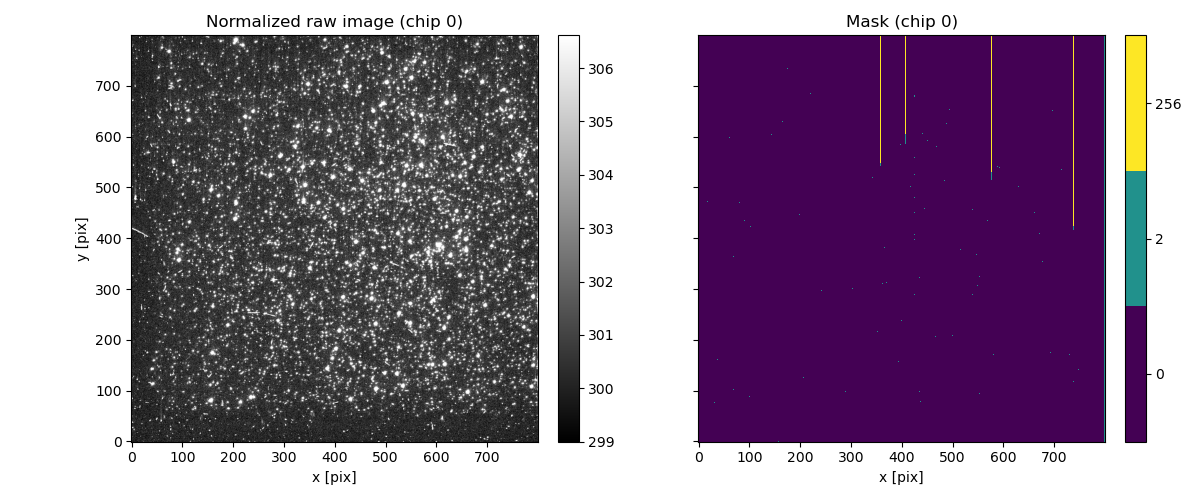

In [6]:
chip = 0  # 0-3 -> DETECTOR 1-4

raw_data = cal['raw']['data'][chip]
mask_data = cal['maskfile']['data'][chip]

raw_norm = ImageNormalize(raw_data, interval=ZScaleInterval())

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

im0 = axes[0].imshow(raw_data, origin='lower', cmap='gray', norm=raw_norm)
axes[0].set_title(f'Normalized raw image (chip {chip})')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

flag_values = [0, 2, 256]
mask_index = np.searchsorted(flag_values, mask_data)  # 0 -> 0, 2 -> 1, 256 -> 2

im1 = axes[1].imshow(mask_index, origin='lower', cmap=plt.get_cmap('viridis', 3),
                     vmin=-0.5, vmax=2.5, interpolation='nearest')
axes[1].set_title(f'Mask (chip {chip})')
cbar1 = fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, ticks=[0, 1, 2])
cbar1.ax.set_yticklabels([str(v) for v in flag_values])

for ax in axes:
    ax.set_xlabel('x [pix]')
axes[0].set_ylabel('y [pix]')

plt.tight_layout()
plt.show()

We can see that some streaks of questionable pixels appear on the image and at the tips of all these streaks, there are invalid pixels. Aside from this, there are several defective pixels scattered across the image, so I consider it necessary to apply the mask in the processing pipeline. I decide to keep the questionable pixels (identifying them) because upon closer inspection of the region, they do not seem to heavily affect the image. 

### 2.2. Apply and verify the mask is correctly applied (using the MASKFILE)
(defective in mask should be equal to NaN in result if we keep the questionable pixels)

In [7]:
masked, questionable = apply_mask(cal)

# Check: every defective pixel should now be NaN, and nothing else
print("defective in mask:", np.sum(cal['maskfile']['data'] == 2))
print("NaN in result:    ", np.sum(np.isnan(masked)))
print("questionable kept:", np.sum(questionable))

defective in mask: 5430
NaN in result:     5430
questionable kept: 13378


### 2.3. Save the masked image 

In [8]:
save_fits(masked, cal['raw']['header'],
          here / "hst-processed" / f"{calibration_image}_masked.fits",
          history="MASKFILE applied: defective (2) set to NaN, questionable (256) kept")

## 3. Remove bias level with the BLEVFILE

In [9]:
bias_corrected, bias_levels = subtract_bias_level(masked, cal['blevfile']['data'])

for chip, (even, odd) in enumerate(bias_levels):
    print(f"chip {chip} (DETECTOR {chip + 1}): even {even:.4f}, odd {odd:.4f}")

# Compare chip 0 with the pipeline's values for DETECTOR 1
c0m_hdr = fits.getheader(here / "hst-data" / "F336W" / f"{calibration_image}_c0m_aligned.fits", 1)
print("pipeline (DETECTOR 1): BIASEVEN", c0m_hdr['BIASEVEN'], " BIASODD", c0m_hdr['BIASODD'])

# NaN pixels should stay NaN, and no new ones should appear
print("NaN before:", np.sum(np.isnan(masked)), " after:", np.sum(np.isnan(bias_corrected)))

save_fits(bias_corrected, cal['raw']['header'],
          here / "hst-processed" / f"{calibration_image}_blev.fits",
          history="BLEVFILE applied: mean overscan bias level subtracted per chip, even/odd columns")

chip 0 (DETECTOR 1): even 299.6214, odd 299.6210
chip 1 (DETECTOR 2): even 319.7682, odd 319.7665
chip 2 (DETECTOR 3): even 313.2902, odd 313.2975
chip 3 (DETECTOR 4): even 291.7025, odd 291.7226
pipeline (DETECTOR 1): BIASEVEN 299.5152  BIASODD 299.5215
NaN before: 5430  after: 5430


If we compare our bias levels (chip 0) with the values from the aligned reference image we are comparing against, we can see that they are very similar, with the small differences likely due to the way this step calculations were defined in their respective pipelines. If we run the notebook for the three files that need calibration, we obtain similar values in all runs.

## 4. Get the header from the raw file and remove bias image with the BIASFILE
The header contains useful metadata that the functions use as inputs

In [10]:
raw_hdr = cal['raw']['header']

debiased = subtract_bias_image(bias_corrected, cal['biasfile']['data'])

## 5. Subtract the dark with the DARKFILE

In [11]:
dark_subtracted = subtract_dark(debiased, cal['darkfile']['data'],
                                dark_time=raw_hdr['DARKTIME'],
                                dark_ref_time=cal['darkfile']['header']['DARKTIME'])

## 6. Flat-field with the FLATFILE
WFPC2 FLATFILEs are inverse flats, so they are multiplied rather than divided

In [12]:
calibrated = apply_flat(dark_subtracted, cal['flatfile']['data'])

save_fits(calibrated, raw_hdr,
          here / "hst-processed" / f"{calibration_image}_calibrated.fits",
          history="BIASFILE subtracted, DARKFILE scaled by DARKTIME subtracted, FLATFILE (inverse flat) multiplied")

## 8. Photometric calibration with the PHOTTAB
The raw header requests this step (DOPHOTOM = PERFORM) but leaves PHOTTAB blank; the pipeline computes the photometry keywords with synphot from GRAPHTAB and COMPTAB instead, which are not part of our data. We use the photometry values given for each filter (DETECTOR 1 only, see PHOTMODE), write them to the header, and convert counts to flux density (erg / s / cm^2 / Angstrom) and STMAG magnitudes

In [13]:
filter_name = raw_hdr['FILTNAM1'].strip()

phot_tables = {
    'F336W': {'PHOTMODE': 'WFPC2,1,A2D15,F336W,,CAL', 'PHOTFLAM': 1.115396e-16, 'PHOTZPT': -21.1,
              'PHOTPLAM': 3359.474, 'PHOTBW': 204.4908, 'ZP_CORR': -0.03288031},
    'F555W': {'PHOTMODE': 'WFPC2,1,A2D15,F555W,,CAL', 'PHOTFLAM': 6.920538e-18, 'PHOTZPT': -21.1,
              'PHOTPLAM': 5442.934, 'PHOTBW': 522.2513, 'ZP_CORR': 0.02655506},
}

phot = phot_tables[filter_name]
print("Filter:", filter_name, "->", phot['PHOTMODE'])

phot_hdr = raw_hdr.copy()
for key, value in phot.items():
    phot_hdr[key] = value

flux = photometric_calibration(calibrated[0], raw_hdr['EXPTIME'], phot['PHOTFLAM'])

# Background pixels with flux <= 0 have no magnitude, so they become NaN
with np.errstate(invalid='ignore', divide='ignore'):
    mag = flux_to_mag(flux, phot['PHOTZPT'], phot['ZP_CORR'])

print("median flux:", np.nanmedian(flux), " brightest pixel (mag):", np.nanmin(mag))

save_fits(flux, phot_hdr,
          here / "hst-processed" / f"{calibration_image}_flux.fits",
          history=f"Photometry keywords for {filter_name} added; counts converted to flux density with PHOTFLAM / EXPTIME")

Filter: F336W -> WFPC2,1,A2D15,F336W,,CAL
median flux: 1.5001654160562785e-19  brightest pixel (mag): 13.782483136849148


## 9. Compare with the pipeline image
The pipeline's photometry step only writes the photometry keywords to the header and leaves the pixels in counts (BUNIT = COUNTS), so its final image is compared with ours in counts. Converting both to flux would multiply every pixel by the same constant (PHOTFLAM / EXPTIME) and change only the axis scale, not the shape of the histograms or the differences

### 9.1. Load the aligned pipeline image
The aligned image is DETECTOR 1 only, so it is compared with chip 0

In [14]:
pipeline_path = here / "hst-data" / filter_name / f"{calibration_image}_c0m_aligned.fits"
pipeline = fits.getdata(pipeline_path, 1)
pipeline_hdr = fits.getheader(pipeline_path, 1)
print("Filter:", filter_name, " pipeline units:", pipeline_hdr.get('BUNIT'))

Filter: F336W  pipeline units: COUNTS


### 9.2. Plot our calibrated image against the pipeline image

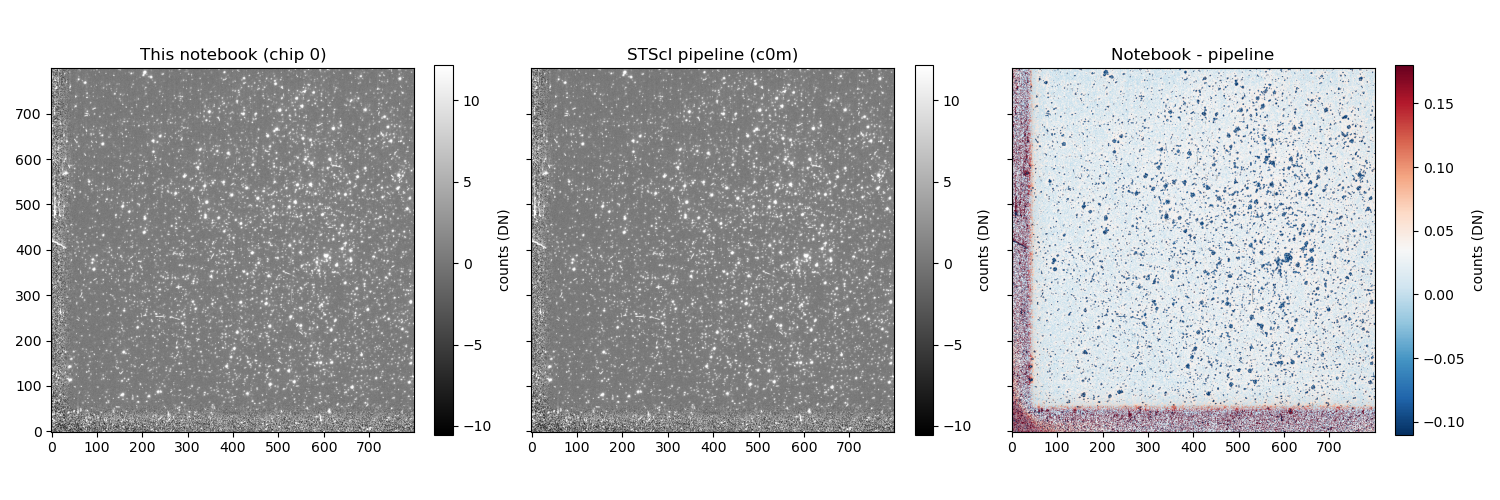

In [15]:
# Same display scaling for both images, so differences are real and not a contrast effect
norm = ImageNormalize(pipeline, interval=ZScaleInterval())
difference = calibrated[0] - pipeline

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
panels = [(calibrated[0], 'This notebook (chip 0)', norm, 'gray'),
          (pipeline, 'STScI pipeline (c0m)', norm, 'gray'),
          (difference, 'Notebook - pipeline', ImageNormalize(difference, interval=ZScaleInterval()), 'RdBu_r')]

for ax, (image, title, image_norm, cmap) in zip(axes, panels):
    im = ax.imshow(image, origin='lower', cmap=cmap, norm=image_norm)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, label='counts (DN)')

plt.tight_layout()
plt.show()

### 9.3. Histogram of pixel values against the pipeline image
Same bins for both images; the y axis is logarithmic so the bright tail (stars) is visible next to the background peak

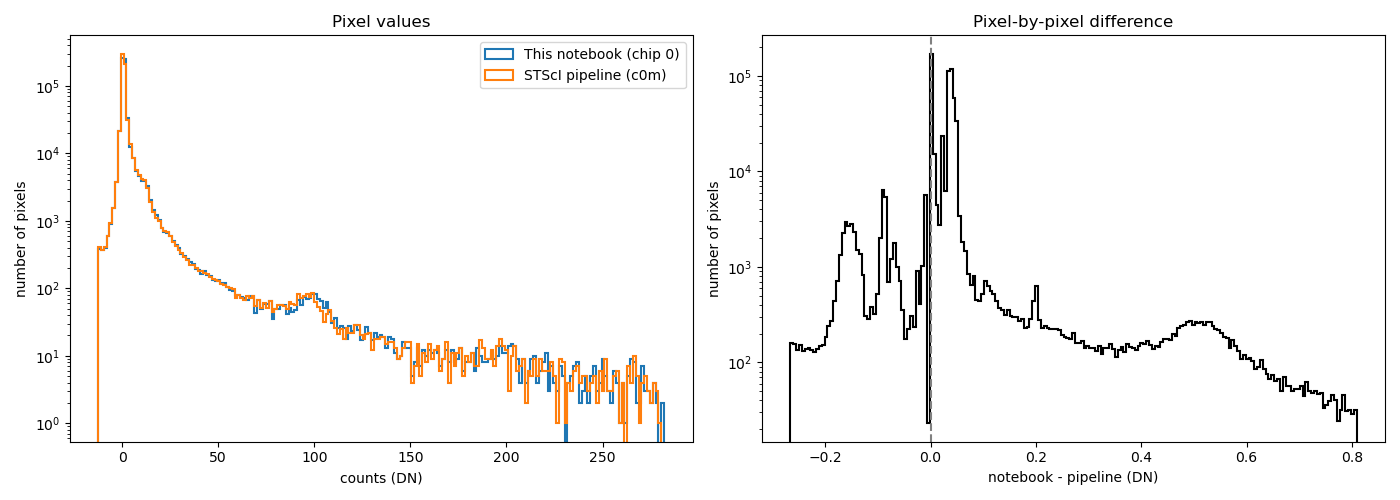

                    median       std    NaN
This notebook        0.807   262.020   1169
STScI pipeline       0.770   261.843      0
Difference           0.035     0.279


In [16]:
mine = calibrated[0][np.isfinite(calibrated[0])]
theirs = pipeline[np.isfinite(pipeline)]
difference_values = difference[np.isfinite(difference)]

low, high = np.percentile(np.concatenate([mine, theirs]), [0.5, 99.9])
bins = np.linspace(low, high, 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(mine, bins=bins, histtype='step', lw=1.5, label='This notebook (chip 0)')
axes[0].hist(theirs, bins=bins, histtype='step', lw=1.5, label='STScI pipeline (c0m)')
axes[0].set_yscale('log')
axes[0].set_xlabel('counts (DN)')
axes[0].set_ylabel('number of pixels')
axes[0].set_title('Pixel values')
axes[0].legend()

diff_low, diff_high = np.percentile(difference_values, [0.5, 99.5])
axes[1].hist(difference_values, bins=np.linspace(diff_low, diff_high, 200), histtype='step', lw=1.5, color='k')
axes[1].axvline(0, color='gray', ls='--')
axes[1].set_yscale('log')
axes[1].set_xlabel('notebook - pipeline (DN)')
axes[1].set_ylabel('number of pixels')
axes[1].set_title('Pixel-by-pixel difference')

plt.tight_layout()
plt.show()

print(f"{'':16} {'median':>9} {'std':>9} {'NaN':>6}")
print(f"{'This notebook':16} {np.median(mine):9.3f} {np.std(mine):9.3f} {np.sum(np.isnan(calibrated[0])):6}")
print(f"{'STScI pipeline':16} {np.median(theirs):9.3f} {np.std(theirs):9.3f} {np.sum(np.isnan(pipeline)):6}")
print(f"{'Difference':16} {np.median(difference_values):9.3f} {np.std(difference_values):9.3f}")